In [1]:
# LIBRERÍAS QUE SE USAN
import tensorflow as tf                  # TensorFlow: CREA Y ENTRENA REDES NEURONALES
import numpy as np                       # NumPy: ARREGLOS Y OPERACIONES CON NÚMEROS
import matplotlib.pyplot as plt          # Matplotlib: GRÁFICAS E IMÁGENES
from tensorflow.keras.models import Sequential      # Sequential: RED CON LAS CAPAS UNA TRAS OTRA
from tensorflow.keras.layers import Flatten, Dense # TIPOS DE CAPA QUE SE USAN ABAJO

# DESCARGAR MNIST: 70,000 IMÁGENES DE DÍGITOS ESCRITOS A MANO.
# x = LAS IMÁGENES, y = LA ETIQUETA CORRECTA (EL NÚMERO DEL 0 AL 9).
# YA VIENE SEPARADO EN DATOS DE ENTRENAMIENTO (60,000) Y DE PRUEBA (10,000).
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [2]:
# CADA PÍXEL VIENE CON UN VALOR DE 0 (NEGRO) A 255 (BLANCO)
gray_scale = 255

# SE DIVIDE ENTRE 255 PARA DEJAR LOS VALORES ENTRE 0 Y 1.
# A LA RED LE CUESTA MENOS APRENDER CON NÚMEROS PEQUEÑOS.
x_train = x_train.astype('float32') / gray_scale
x_test = x_test.astype('float32') / gray_scale

# REVISAR LOS TAMAÑOS:
# (60000, 28, 28) = 60,000 IMÁGENES DE 28X28 PÍXELES; (60000,) = UNA ETIQUETA POR IMAGEN
print("Feature matrix (x_train):", x_train.shape)
print("Target matrix (y_train):", y_train.shape)
print("Feature matrix (x_test):", x_test.shape)
print("Target matrix (y_test):", y_test.shape)

Feature matrix (x_train): (60000, 28, 28)
Target matrix (y_train): (60000,)
Feature matrix (x_test): (10000, 28, 28)
Target matrix (y_test): (10000,)


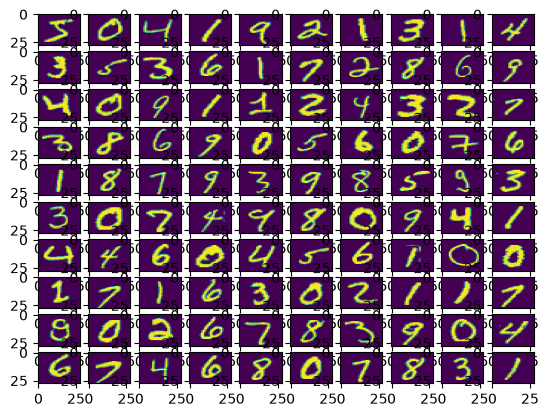

In [3]:
# MOSTRAR LAS PRIMERAS 100 IMÁGENES DEL ENTRENAMIENTO EN UNA CUADRÍCULA DE 10X10
fig, ax = plt.subplots(10, 10)   # CREA 100 ESPACIOS PARA DIBUJAR
k = 0                            # ÍNDICE DE LA IMAGEN QUE SE VA A MOSTRAR
for i in range(10):              # FILAS
    for j in range(10):          # COLUMNAS
        ax[i][j].imshow(x_train[k].reshape(28, 28), aspect='auto')
        k += 1
plt.show()

In [4]:
# CREAR LA RED NEURONAL (PERCEPTRÓN MULTICAPA) CON 4 PASOS, UNO TRAS OTRO:
model = Sequential([
    # Flatten: CONVIERTE CADA IMAGEN DE 28X28 EN UNA FILA DE 784 VALORES (28*28)
    Flatten(input_shape=(28, 28)),
    # CAPA OCULTA DE 256 NEURONAS CON ACTIVACIÓN sigmoid (VALORES ENTRE 0 Y 1)
    Dense(256, activation='sigmoid'),  
    # CAPA OCULTA DE 128 NEURONAS, TAMBIÉN sigmoid
    Dense(128, activation='sigmoid'), 
    # CAPA DE SALIDA: 10 NEURONAS, UNA POR CADA DÍGITO (0-9).
    #    softmax HACE QUE LAS 10 SALIDAS SUMEN 1, O SEA QUE SON PROBABILIDADES
    Dense(10, activation='softmax'),  
])
# (EL AVISO ROJO SOBRE input_shape QUE SALE AL CORRER ESTA CELDA NO AFECTA EL RESULTADO)

c:\Users\OSCAR\Trabajos-Inteligencia-Artificial\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [5]:
# CONFIGURAR CÓMO VA A APRENDER LA RED
model.compile(optimizer='adam',                        # Adam: ALGORITMO QUE AJUSTA LOS PESOS
              loss='sparse_categorical_crossentropy',  # pérdida: MIDE QUÉ TANTO SE EQUIVOCA ENTRE VARIAS CLASES
              metrics=['accuracy'])                    # accuracy: PORCENTAJE DE ACIERTOS

In [6]:
# ENTRENAR LA RED
# epochs = CUÁNTAS VECES LA RED VE TODOS LOS DATOS DE ENTRENAMIENTO
#          (MÁS ÉPOCAS = APRENDE MÁS, PERO DEMASIADAS CAUSAN OVERFITTING)
# batch_size = CUÁNTAS IMÁGENES PROCESA ANTES DE AJUSTAR LOS PESOS
# validation_split = 20% DE LOS DATOS SE SEPARAN PARA IR COMPROBANDO SI GENERALIZA BIEN
mod = model.fit(x_train, y_train, epochs=30, 
          batch_size=2000, 
          validation_split=0.2)
          
# 'mod' GUARDA EL HISTORIAL DEL ENTRENAMIENTO (SE USA ABAJO PARA LAS GRÁFICAS)
print(mod)

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4440 - loss: 2.0640 - val_accuracy: 0.6946 - val_loss: 1.6933
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7473 - loss: 1.3450 - val_accuracy: 0.8216 - val_loss: 0.9842
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8269 - loss: 0.8249 - val_accuracy: 0.8591 - val_loss: 0.6423
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8619 - loss: 0.5853 - val_accuracy: 0.8849 - val_loss: 0.4853
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8832 - loss: 0.4659 - val_accuracy: 0.8977 - val_loss: 0.4035
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8949 - loss: 0.3994 - val_accuracy: 0.9067 - val_loss: 0.3552
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9044 - loss: 0.3564 - val_accuracy: 0.9132 - val_loss: 0.3218
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9106 - loss: 0.3258 - val_accuracy: 0.9180 - val_loss:

In [7]:
# PROBAR EL MODELO CON LOS 10,000 DATOS DE PRUEBA, QUE NUNCA VIO AL ENTRENAR
results = model.evaluate(x_test, y_test, verbose=0)
# IMPRIME [PÉRDIDA, PRECISIÓN]; LA PRECISIÓN ES EL PORCENTAJE DE ACIERTOS (0.95 = 95%)
print('Test loss, Test accuracy:', results)

Test loss, Test accuracy: [0.1349155455827713, 0.9592999815940857]


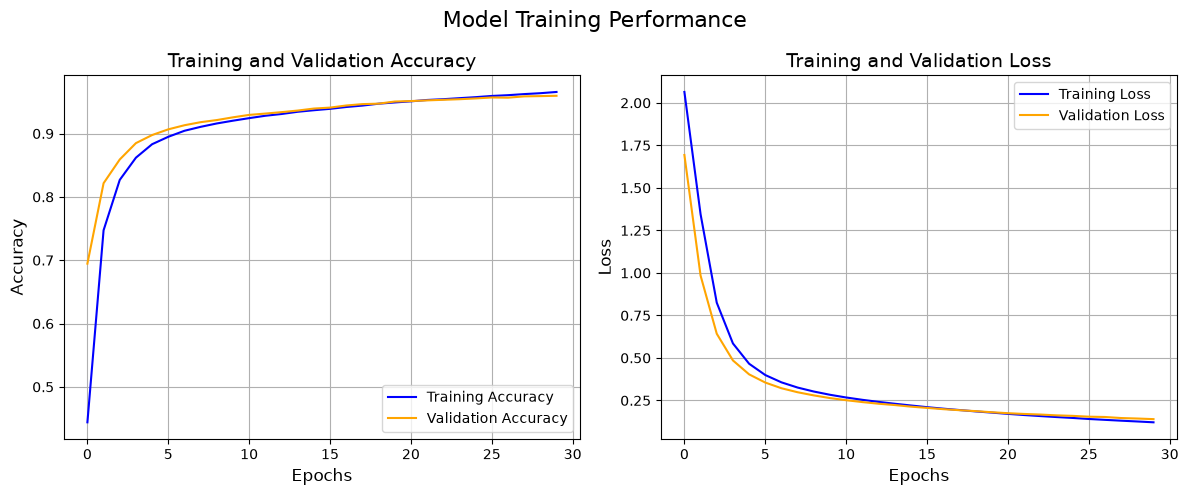

In [8]:
# GRÁFICAS DEL ENTRENAMIENTO: AZUL = DATOS DE ENTRENAMIENTO, NARANJA = VALIDACIÓN
plt.figure(figsize=(12, 5))

# GRÁFICA IZQUIERDA: PRECISIÓN POR ÉPOCA (DEBE SUBIR)
plt.subplot(1, 2, 1)
plt.plot(mod.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(mod.history['val_accuracy'],
         label='Validation Accuracy', color='orange')
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend()
plt.grid(True)

# GRÁFICA DERECHA: PÉRDIDA POR ÉPOCA (DEBE BAJAR).
# SI LA NARANJA EMPIEZA A SUBIR MIENTRAS LA AZUL BAJA, HAY OVERFITTING
plt.subplot(1, 2, 2)
plt.plot(mod.history['loss'], label='Training Loss', color='blue')
plt.plot(mod.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True)

plt.suptitle("Model Training Performance", fontsize=16)
plt.tight_layout()
plt.show()

In [9]:
# GUARDA EL MODELO ENTRENADO EN UN ARCHIVO. SE CREA EN LA MISMA CARPETA QUE ESTE ARCHIVO.

model.save("mlp_model.keras")
print("Modelo guardado en mlp_model.keras")

Modelo guardado en mlp_model.keras


In [10]:
import tkinter as tk                              # tkinter: CREA VENTANAS, BOTONES Y LIENZOS (YA VIENE CON PYTHON)

from PIL import Image, ImageDraw                  # Pillow: CREAR Y DIBUJAR IMÁGENES
from tensorflow.keras.models import load_model    # PARA LEER UN MODELO GUARDADO

# CARGAR EL MODELO GUARDADO EN LA CELDA ANTERIOR.
# YA TRAE LA ARQUITECTURA Y LOS PESOS APRENDIDOS, POR ESO NO HAY QUE ENTRENAR OTRA VEZ.
modelo = load_model("mlp_model.keras")

# MOSTRAR LAS CAPAS DEL MODELO: Flatten (784), Dense 256, Dense 128 y Dense 10
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

In [11]:
def preparar_imagen(imagen):
    # RECIBE EL DIBUJO DE 280X280 Y DEVUELVE UNA IMAGEN DE 28X28 LISTA PARA EL MODELO.
    # DEVUELVE None SI NO HAY NADA DIBUJADO.

    # PASO 1: ENCONTRAR DÓNDE HAY TRAZO (PÍXELES DISTINTOS DE 0, O SEA, NO NEGROS)
    pixeles = np.array(imagen)              # LA IMAGEN COMO ARREGLO DE NÚMEROS
    ys, xs = np.where(pixeles > 0)          # POSICIONES (FILA, COLUMNA) DE LOS PÍXELES CON TRAZO
    if len(xs) == 0:                        # NO HAY NINGÚN TRAZO
        return None

    # PASO 2: RECORTAR LA CAJA QUE RODEA AL DÍGITO (SE QUITA EL FONDO NEGRO SOBRANTE)
    recorte = imagen.crop((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1))

    # PASO 3: REDUCIR PARA QUE EL LADO MÁS GRANDE MIDA 20 PÍXELES
    # (EN MNIST LOS DÍGITOS OCUPAN 20X20 DENTRO DE LA IMAGEN DE 28X28)
    ancho, alto = recorte.size
    escala = 20 / max(ancho, alto)          # CUÁNTO HAY QUE REDUCIR
    nuevo_ancho = max(1, round(ancho * escala))
    nuevo_alto = max(1, round(alto * escala))
    recorte = recorte.resize((nuevo_ancho, nuevo_alto), Image.LANCZOS)

    # PASO 4: PEGARLO EN EL CENTRO DE UN FONDO NEGRO DE 28X28
    imagen28 = Image.new("L", (28, 28), 0)  # "L" = ESCALA DE GRISES, 0 = NEGRO
    imagen28.paste(recorte, ((28 - nuevo_ancho) // 2, (28 - nuevo_alto) // 2))

    # PASO 5: CENTRAR POR CENTRO DE MASA (ASÍ SE CENTRÓ MNIST).
    # EL CENTRO DE MASA ES EL "PUNTO DE EQUILIBRIO" DEL TRAZO, PONDERADO POR EL BRILLO DE CADA PÍXEL.
    arreglo = np.array(imagen28, dtype="float32")
    ys, xs = np.indices(arreglo.shape)      # COORDENADAS DE CADA PÍXEL
    masa = arreglo.sum()                    # SUMA DE TODO EL BRILLO
    cx = (xs * arreglo).sum() / masa        # CENTRO DE MASA EN HORIZONTAL
    cy = (ys * arreglo).sum() / masa        # CENTRO DE MASA EN VERTICAL
    desplazada = Image.new("L", (28, 28), 0)
    # MOVER LA IMAGEN LO NECESARIO PARA QUE EL CENTRO DE MASA CAIGA EN (14, 14), EL CENTRO
    desplazada.paste(imagen28, (round(14 - cx), round(14 - cy)))
    return desplazada

In [12]:
def predecir_digito(imagen28):
    # RECIBE LA IMAGEN DE 28X28 Y DEVUELVE (DÍGITO PREDICHO, LAS 10 PROBABILIDADES)
    global ultima_entrada
    ultima_entrada = imagen28                      # SE GUARDA PARA PODER VERLA DESPUÉS EN LA ÚLTIMA CELDA

    # MISMO PREPROCESAMIENTO DEL ENTRENAMIENTO: PASAR DE 0-255 A 0-1
    x = np.array(imagen28, dtype="float32") / gray_scale

    # EL MODELO ESPERA UN LOTE DE IMÁGENES: (CANTIDAD, 28, 28). AQUÍ ES UN LOTE DE 1 IMAGEN
    x = x.reshape(1, 28, 28)

    # predict DEVUELVE UNA FILA POR IMAGEN; [0] TOMA LA DE NUESTRA ÚNICA IMAGEN.
    # SON 10 VALORES: LA PROBABILIDAD DE QUE SEA 0, 1, 2, ..., 9
    probabilidades = modelo.predict(x, verbose=0)[0]

    # argmax DEVUELVE LA POSICIÓN DE LA PROBABILIDAD MÁS ALTA, QUE ES EL DÍGITO PREDICHO
    digito = int(np.argmax(probabilidades))
    return digito, probabilidades

In [13]:
TAMANO_LIENZO = 280        # EL LIENZO MIDE 280X280, 10 VECES LOS 28X28 DE MNIST
GROSOR_TRAZO = 25          # TRAZO GRUESO, PARECIDO AL DE LOS DÍGITOS DE MNIST
ANCHO_BARRA = 180          # LARGO (EN PÍXELES) DE UNA BARRA AL 100 %
ALTO_FILA = 22             # ALTO DE CADA FILA DE LA GRÁFICA
COLOR_BARRA = "#b8b8b8"    # GRIS: DÍGITOS QUE NO SE ELIGIERON
COLOR_GANADOR = "#9D00FF"  # MORADO: EL DÍGITO PREDICHO (SE PUEDE CAMBIAR POR OTRO COLOR)


def abrir_ventana():
    ventana = tk.Tk()                                   # CREAR LA VENTANA PRINCIPAL
    ventana.title("Reconocedor de dígitos (MLP + MNIST)")
    ventana.attributes("-topmost", True)                # QUE APAREZCA AL FRENTE

    # LA VENTANA SE DIVIDE EN DOS COLUMNA: A LA IZQUIERDA SE DIBUJA, A LA DERECHA SE VEN LOS RESULTADOS
    izquierda = tk.Frame(ventana)
    izquierda.pack(side="left", padx=10, pady=10)
    derecha = tk.Frame(ventana)
    derecha.pack(side="left", padx=(0, 10), pady=10)

    # EL LIENZO ES EL CUADRO NEGRO DONDE SE DIBUJA CON EL MOUSE
    lienzo = tk.Canvas(izquierda, width=TAMANO_LIENZO, height=TAMANO_LIENZO,
                       bg="black", cursor="cross")
    lienzo.pack()

    # COPIA DEL DIBUJO EN MEMORIA (0 = NEGRO, 255 = BLANCO).
    # LO QUE SE VE EN EL LIENZO ES SOLO VISUAL; ESTA IMAGEN ES LA QUE SE MANDA AL MODELO.
    imagen = Image.new("L", (TAMANO_LIENZO, TAMANO_LIENZO), 0)
    pincel = ImageDraw.Draw(imagen)                     # HERRAMIENTA PARA DIBUJAR SOBRE ESA IMAGEN
    ultimo = [None]   # ÚLTIMO PUNTO DEL MOUSE (LISTA PARA QUE LAS FUNCIONES DE ABAJO PUEDAN CAMBIARLO)

    # COLUMNA DERECHA: TEXTO DEL RESULTADO Y GRÁFICA DE BARRAS
    resultado = tk.Label(derecha, text="Dibuja un número\ndel 0 al 9", font=("Arial", 14))
    grafica = tk.Canvas(derecha, width=270, height=10 * ALTO_FILA)

    def mostrar_barras(probabilidades, ganador):
        # UNA FILA POR DÍGITO: EL LARGO DE LA BARRA ES SU PROBABILIDAD
        grafica.delete("all")                           # BORRAR LA GRÁFICA ANTERIOR
        for d, p in enumerate(probabilidades):          # d = DÍGITO, p = PROBABILIDAD (0 a 1)
            y = d * ALTO_FILA + 3                       # ALTURA DE ESTA FILA
            largo = p * ANCHO_BARRA                     # 100 % = ANCHO_BARRA   PÍXELES
            color = COLOR_GANADOR if d == ganador else COLOR_BARRA
            grafica.create_text(8, y + 8, text=str(d), font=("Consolas", 10))
            grafica.create_rectangle(24, y, 24 + largo, y + 16, fill=color, width=0)
            grafica.create_text(30 + largo, y + 8, text=f"{p * 100:.1f}%",
                                anchor="w", font=("Consolas", 9))

    def empezar_trazo(evento):
        # AL PRESIONAR EL MOUSE: GUARDA DÓNDE EMPIEZA EL TRAZO
        ultimo[0] = (evento.x, evento.y)
        dibujar(evento)

    def dibujar(evento):
        # SE LLAMA CADA VEZ QUE EL MOUSE SE MUEVE CON EL BOTÓN PRESIONADO
        x0, y0 = ultimo[0]                  # PUNTO ANTERIOR
        x1, y1 = evento.x, evento.y         # PUNTO ACTUAL
        # SE DIBUJA UNA LÍNEA DEL PUNTO ANTERIOR AL ACTUAL, EN DOS LUGARES:
        # 1) EN PANTALLA (EL LIENZO)
        lienzo.create_line(x0, y0, x1, y1, fill="white",
                           width=GROSOR_TRAZO, capstyle=tk.ROUND)
        # 2) EN LA IMAGEN EN MEMORIA
        pincel.line([x0, y0, x1, y1], fill=255, width=GROSOR_TRAZO)
        r = GROSOR_TRAZO // 2
        pincel.ellipse([x1 - r, y1 - r, x1 + r, y1 + r], fill=255)  # PUNTA REDONDA
        ultimo[0] = (x1, y1)                # EL PUNTO ACTUAL PASA A SER EL ANTERIOR

    def borrar():
        # LIMPIAR EL LIENZO, LA IMAGEN EN MEMORIA, EL TEXTO Y LA GRÁFICA
        lienzo.delete("all")
        pincel.rectangle([0, 0, TAMANO_LIENZO, TAMANO_LIENZO], fill=0)
        resultado.config(text="Dibuja un número\ndel 0 al 9")
        grafica.delete("all")

    def predecir():
        # SE LLAMA AL PRESIONAR EL BOTÓN PREDECIR
        imagen28 = preparar_imagen(imagen)          # DEJAR EL DIBUJO COMO IMAGEN DE MNIST
        if imagen28 is None:                        # NO SE DIBUJÓ NADA
            resultado.config(text="Primero dibuja\nun número")
            return
        digito, probabilidades = predecir_digito(imagen28)   # EL MODELO DECIDE
        resultado.config(
            text=f"Creo que es un {digito}\n({probabilidades[digito] * 100:.1f}%)")
        mostrar_barras(probabilidades, digito)

    # CONECTAR EL MOUSE CON LAS FUNCIONES:
    lienzo.bind("<Button-1>", empezar_trazo)    # CLIC IZQUIERDO PRESIONADO
    lienzo.bind("<B1-Motion>", dibujar)         # MOUSE EN MOVIMIENTO CON CLIC PRESIONADO

    # BOTONES PREDECIR Y BORRAR DEBAJO DEL LIENZO, UNO AL LADO DEL OTRO
    botones = tk.Frame(izquierda)
    botones.pack(pady=(10, 0))
    tk.Button(botones, text="Predecir", width=12, command=predecir).pack(side="left", padx=5)
    tk.Button(botones, text="Borrar", width=12, command=borrar).pack(side="left", padx=5)

    # COLUMNA DERECHA: PRIMERO EL TEXTO Y DEBAJO LA GRÁFICA
    resultado.pack(pady=(0, 10))
    grafica.pack()

    # mainloop MANTIENE LA VENTANA ABIERTA Y ATENTA AL MOUSE HASTA QUE SE CIERRE.
    # POR ESO LA CELDA NO TERMINA HASTA QUE CIERRES LA VENTANA.
    ventana.mainloop()


abrir_ventana()

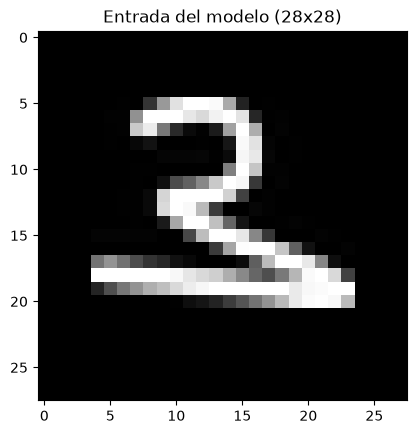

In [14]:
# MOSTRAR LA ÚLTIMA IMAGEN DE 28X28 QUE RECIBIÓ EL MODELO (LA GUARDÓ PREDECIR_DIGITO).
# SIRVE PARA COMPARAR CON LOS DÍGITOS DE MNIST Y VER POR QUÉ SE EQUIVOCÓ, SI ES EL CASO.
plt.imshow(ultima_entrada, cmap="gray")
plt.title("Entrada del modelo (28x28)")
plt.show()